# Case Study: Classifying Fake vs. Factual News

**Scenario:** a social media company is worried about fake news on its platform. We investigate how fake and factual articles differ and build a classifier to tell them apart. Walkthrough of `src/analyze.py`.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
import analyze

pd.set_option('display.max_colwidth', 110)

## 1. The data

In [2]:
df = analyze.load_data()
df[['title', 'text', 'fake_or_factual']].head()

,title,text,fake_or_factual
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim Refugees To Jesus’ Family,There are two small problems with your analogy Susan Jesus was NOT a Muslim and Joseph traveled to Bethle...,Fake News
1,Elijah Cummings Called Trump Out To His Face And Here’s The Pathetic Way Trump Tried To Spin It,Buried in Trump s bonkers interview with New York Times reporters Maggie Haberman and Glenn Thrush is this...,Fake News
2,Hillary Clinton Says Half Her Cabinet Will Be Women If Elected President,"Women make up over 50 percent of this country, but are grossly underrepresented in just about everything. ...",Fake News
3,Russian bombing of U.S.-backed forces being discussed at 'highest levels': Mattis,WASHINGTON (Reuters) - U.S. Defense Secretary Jim Mattis said on Monday that Russia s bombing of U.S-backe...,Factual News
4,Britain says window to restore Northern Ireland devolution closing rapidly,BELFAST (Reuters) - Northern Ireland s political parties are rapidly running out of time to restore a devo...,Factual News


In [3]:
df['fake_or_factual'].value_counts()

fake_or_factual
Factual News    100
Fake News        98
Name: count, dtype: int64

In [4]:
df.groupby('fake_or_factual')['words'].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
fake_or_factual,,,,,,,,
Factual News,100.0,348.0,261.0,28.0,122.0,312.0,478.0,1070.0
Fake News,98.0,403.0,352.0,13.0,225.0,368.0,477.0,3141.0


The classes are balanced (100 factual, 98 fake), so accuracy is a fair metric and 50% is the chance baseline. Look at how the articles *start*:

In [5]:
for label in analyze.LABELS:
    print(label)
    for t in df[df['fake_or_factual'] == label]['text'].head(3):
        print('  ', t[:110])

Factual News
   WASHINGTON (Reuters) - U.S. Defense Secretary Jim Mattis said on Monday that Russia s bombing of U.S-backed fi
   BELFAST (Reuters) - Northern Ireland s political parties are rapidly running out of time to restore a devolved
   (Reuters) - Seattle financial worker Harrison Karlewicz had been considering joining an environmental activist
Fake News
   There are two small problems with your analogy Susan  Jesus was NOT a Muslim and Joseph traveled to Bethlehem 
   Buried in Trump s bonkers interview with New York Times reporters Maggie Haberman and Glenn Thrush is this out
   Women make up over 50 percent of this country, but are grossly underrepresented in just about everything. In t


Every factual article opens with a Reuters dateline ("WASHINGTON (Reuters) -"). Keep that in mind: it is a giveaway a classifier could exploit without understanding anything about truthfulness.

## 2. How do the two kinds of article differ?

### Part of speech

In [6]:
tags = analyze.tag_texts(df)
shares = analyze.pos_shares(df, tags)
(shares * 100).round(1)

fake_or_factual,Factual News,Fake News
NOUN,20.0,19.1
PROPN,17.0,14.2
VERB,12.9,13.3
ADJ,7.2,6.4
ADV,2.4,3.9
PRON,5.1,7.9


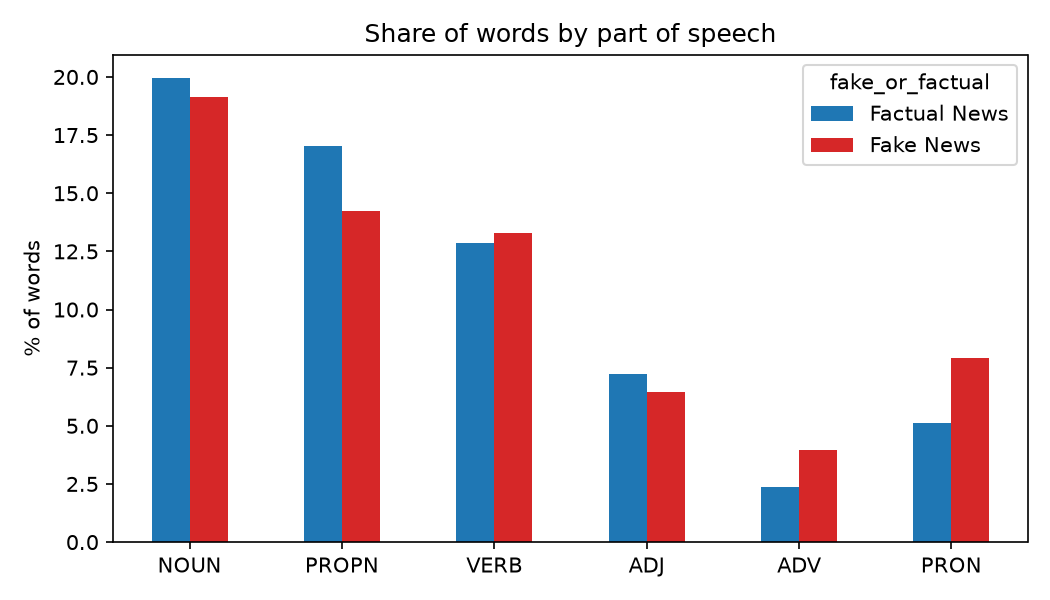

In [7]:
analyze.plot_pos(shares)
from IPython.display import Image
Image('../outputs/pos_shares.png', width=480)

Fake news uses more **pronouns** (8% vs 5%, a more personal, direct style) and more **adverbs**, and fewer **proper nouns**. Factual reporting is denser in names and places.

### Named entities

In [8]:
ents = {c: analyze.top_entities(df, tags, c) for c in analyze.LABELS}
pd.concat(ents, axis=1)

Factual News                      Fake News              
              entity    type count           entity    type count
0               U.S.     GPE   138            Trump     ORG   143
1            Reuters     ORG   131            Trump  PERSON    78
2              Trump     ORG   120          Clinton  PERSON    74
3              Trump  PERSON    71     Donald Trump  PERSON    63
4  the United States     GPE    49            Obama  PERSON    49
5       Donald Trump  PERSON    45            Syria     GPE    42
6         Republican    NORP    45       Republican    NORP    41
7              Obama  PERSON    38           McCain  PERSON    39
8             Israel     GPE    38          America     GPE    36
9              Syria     GPE    36  Hillary Clinton  PERSON    34

Both are dominated by US politics. Factual news mentions places (U.S., Israel, Syria) and, tellingly, *Reuters* itself 131 times. Fake news is about people: Clinton, Obama, McCain. (The small spaCy model sometimes tags "Trump" as an organisation.)

### Sentiment

In [9]:
df = analyze.add_sentiment(df)
pd.crosstab(df['fake_or_factual'], df['sentiment_label'], normalize='index').round(2)

sentiment_label,negative,neutral,positive
fake_or_factual,,,
Factual News,0.47,0.01,0.52
Fake News,0.47,0.05,0.48


Sentiment is **not** a distinguishing signal: both types are about half negative, half positive. Fake news is not simply angrier.

## 3. Classification

TF-IDF features and a linear classifier, evaluated with repeated 5-fold cross-validation. We train on three versions of the text, to see how much the Reuters dateline matters.

In [10]:
res = analyze.compare_variants(df)
res.assign(accuracy=res['accuracy'].round(3), std=res['std'].round(3))

,text,model,accuracy,std
0,Raw text,Logistic regression,0.923,0.041
1,Raw text,Linear SVM,0.939,0.038
2,Dateline removed,Logistic regression,0.904,0.043
3,Dateline removed,Linear SVM,0.921,0.043
4,Dateline + source removed,Logistic regression,0.904,0.043
5,Dateline + source removed,Linear SVM,0.920,0.043


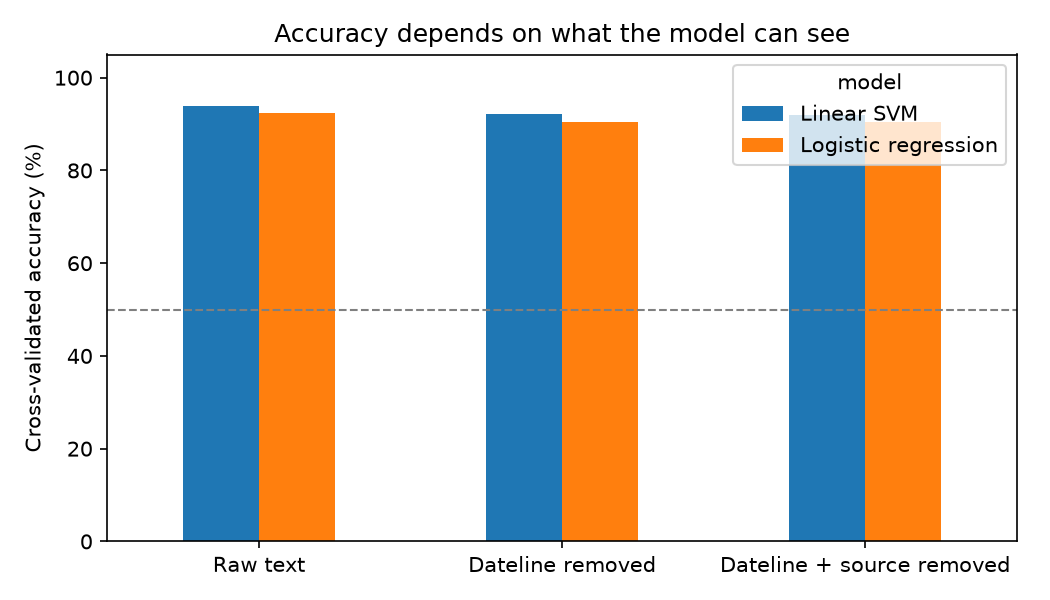

In [11]:
analyze.plot_variants(res)
Image('../outputs/accuracy_by_variant.png', width=520)

Both models reach 90-94%. Removing the dateline and every mention of Reuters costs only about 2 points, so the dateline is *not* the only thing the model relies on. What else is it using?

In [12]:
w_raw = analyze.feature_weights(df, analyze.VARIANTS['Raw text'])
w_clean = analyze.feature_weights(df, analyze.strip_source)
w_clean.round(2)

,factual word,factual weight,fake word,fake weight
0,said,-1.16,just,0.66
1,minister,-0.79,hillary,0.60
2,reporters,-0.58,america,0.58
3,friday,-0.55,clinton,0.56
4,wednesday,-0.55,com,0.55
5,tuesday,-0.52,image,0.53
6,prime,-0.45,pic,0.53
7,statement,-0.40,featured,0.52
8,state,-0.40,gop,0.47
9,chinese,-0.38,women,0.45


The heaviest words in the cleaned model are not about truthfulness:

- **Factual:** *said, minister, reporters, statement* and weekday names (*friday, wednesday, tuesday*): the vocabulary of wire reporting.
- **Fake:** *com, pic, image, featured, just, like, let*: leftovers from embedded tweets, images and links, plus chatty, partisan language (*hillary, gop, america*).

The model is detecting **writing style and publishing format**, i.e. wire-service news vs. hyperpartisan blog posts, not whether the claims are false.

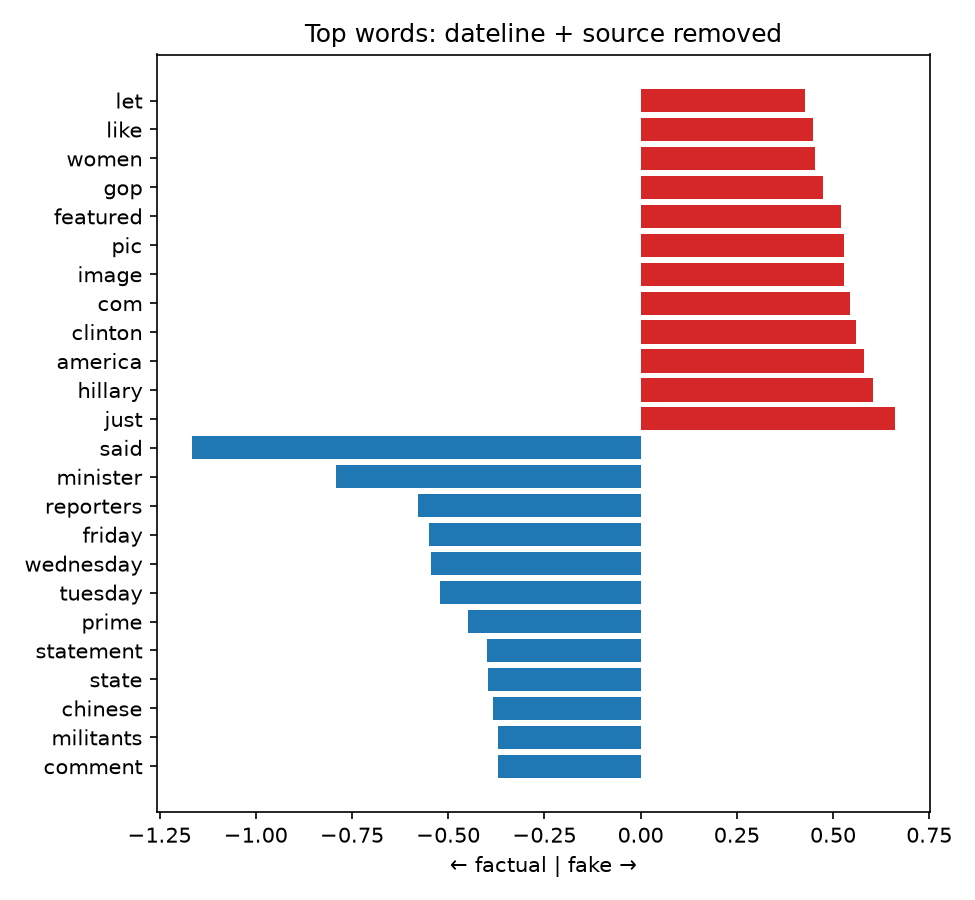

In [13]:
analyze.plot_weights(w_clean, 'Top words: dateline + source removed', 'weights_clean.png')
Image('../outputs/weights_clean.png', width=480)

### Where it goes wrong

In [14]:
from sklearn.model_selection import cross_val_predict
pred = analyze.cv_confusion(df, analyze.strip_source)
errors = df.assign(predicted=pred)[lambda d: d['predicted'] != d['fake_or_factual']]
print(len(errors), 'of', len(df), 'misclassified')
errors[['title', 'fake_or_factual', 'predicted', 'words']]

14 of 198 misclassified


,title,fake_or_factual,predicted,words
11,Kerry says can't comment on content of Clinton emails,Factual News,Fake News,76
20,"BREAKING: Federal Judge STOPS Obamacare Transgender, Abortion Related Protections",Fake News,Factual News,335
24,Putin Just Spit In America’s Face And Trump THANKED Him For It (DETAILS),Fake News,Factual News,377
47,BOMBSHELL: COMEY Wanted To Expose Russian Meddling Months Before Election…OBAMA Regime Barred Him From Tel...,Fake News,Factual News,288
65,House No. 2 Republican says still questions Clinton's judgment in email matter,Factual News,Fake News,71
84,Locker room talk? Key women voters call foul on Trump's defense,Factual News,Fake News,669
88,MUELLER’S FBI RAID Of Paul Manafort and Wife Proves Special Council’s Agents Playing Too Rough,Fake News,Factual News,215
120,Mosley would have kept Ecclestone at F1 helm,Factual News,Fake News,555
125,"For inspiration, new Democratic stars look to Elizabeth Warren",Factual News,Fake News,913
137,BREAKING: TRUMP Announces “Phenomenal” Tax Cut Plan For Businesses In Next 2-3 Weeks…Stock Markets Respond...,Fake News,Factual News,304


## Findings to communicate

1. **A simple model separates these two sources at ~90-92%.** That is well above the 50% baseline.
2. **But it is learning style, not truth.** Wire-service phrasing and web-embed artifacts drive the result, so it would probably fail on a fake story written like a news report, or on factual reporting from a blog.
3. **Sentiment doesn't help;** part-of-speech mix and vocabulary do.
4. **Before deploying anything,** we would need data from many sources per class, articles from different time periods, and ideally human fact-checks as labels.